# Integracion: DroidCam + ArUco + Clasificacion + StockFish

Cuadernillo actualizado con las rutas y cambios actuales del proyecto.

Flujo:
1. Leer camara DroidCam por IP o webcam virtual.
2. Detectar 4 ArUco y enderezar el tablero.
3. Segmentar 64 casillas.
4. Cargar el modelo entrenado desde `Modelo de Clasificacion/outputs`.
5. Clasificar cada casilla.
6. Convertir la posicion a matriz y `python-chess`.
7. Pedir a StockFish la jugada de negras.
8. Actualizar el tablero interno. El brazo robotico se mantiene omitido por ahora.


## 1. Instalacion opcional

In [ ]:
# Ejecuta solo si falta alguna libreria:
# !pip install opencv-contrib-python numpy matplotlib torch torchvision python-chess pillow


## 2. Imports, rutas y configuracion

Las IPs de DroidCam pueden cambiar. Ajusta `DROIDCAM_DEVICE_IP` y `DROIDCAM_WIFI_IP` si DroidCam muestra otros valores.

In [10]:
from pathlib import Path
import json
import time
import subprocess
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import clear_output, display, SVG

import torch
import torch.nn as nn
from torchvision import transforms

import chess
import chess.engine
import chess.svg


def encontrar_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for p in [start, *start.parents]:
        if (p / "Dataset").exists() and (p / "Modelo de Clasificacion").exists():
            return p
    return Path.cwd()

ROOT = encontrar_root()

DATASET_DIR = ROOT / "Dataset"
ENTRENAMIENTO_DIR = DATASET_DIR / "Entrenamiento"
CAMERA_OUTPUT_DIR = DATASET_DIR / "integracion_camara_stockfish"
CAMERA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_OUTPUT_DIR = ROOT / "Modelo de Clasificacion" / "outputs"
MODEL_PATH = MODEL_OUTPUT_DIR / "modelo_ajedrez_entrenamiento.pth"
CLASS_NAMES_PATH = MODEL_OUTPUT_DIR / "class_names.json"

STOCKFISH_CANDIDATES = [
    ROOT / "StockFish" / "stockfish-windows-x86-64-avx2.exe",
    ROOT / "StockFish" / "stockfish" / "stockfish-windows-x86-64-avx2.exe",
]

# DroidCam: deja varias opciones para que el notebook encuentre la que este activa.
DROIDCAM_DEVICE_IP = "192.168.1.6"
DROIDCAM_WIFI_IP = "10.204.120.246"
DROIDCAM_PORT = 4747

CAMERA_SOURCE = f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video"
DROIDCAM_URLS = [
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/mjpegfeed",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video?640x480",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/mjpegfeed",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/video?640x480",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/",
]

CAMERA_BACKENDS = [
    (cv2.CAP_DSHOW, "CAP_DSHOW"),
    (cv2.CAP_MSMF, "CAP_MSMF"),
    (cv2.CAP_ANY, "CAP_ANY"),
]
CAMERA_BACKEND_ACTUAL = None
CAMERA_WIDTH = 1280
CAMERA_HEIGHT = 720

ARUCO_DICT = cv2.aruco.DICT_4X4_50
BOARD_SIZE = 800
CELL_MARGIN = 0.00

STOCKFISH_TIME_LIMIT = 0.5
BLACK_TO_MOVE = chess.BLACK

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("ROOT:", ROOT)
print("Modelo:", MODEL_PATH)
print("Class names:", CLASS_NAMES_PATH)
print("StockFish candidatos:", STOCKFISH_CANDIDATES)
print("DroidCam fuente inicial:", CAMERA_SOURCE)
print("Device:", device)


ROOT: c:\Users\User\Desktop\Brazo Robotico
Modelo: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs\modelo_ajedrez_entrenamiento.pth
Class names: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs\class_names.json
StockFish candidatos: [WindowsPath('c:/Users/User/Desktop/Brazo Robotico/StockFish/stockfish-windows-x86-64-avx2.exe'), WindowsPath('c:/Users/User/Desktop/Brazo Robotico/StockFish/stockfish/stockfish-windows-x86-64-avx2.exe')]
DroidCam fuente inicial: http://192.168.1.6:4747/video
Device: cuda


## 3. Utilidades de camara DroidCam

- Para IP directa: cierra DroidCam Client en Windows y deja abierta la app del celular.
- Para webcam virtual: deja DroidCam Client abierto y prueba indices locales.

In [11]:
def mostrar_frame_notebook(frame_bgr, titulo="Frame", figsize=(8, 5)):
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=figsize)
    plt.imshow(frame_rgb)
    plt.title(titulo)
    plt.axis("off")
    plt.show()


def abrir_video_capture(source, backend=None):
    if isinstance(source, int):
        if backend is None:
            backend = CAMERA_BACKEND_ACTUAL if CAMERA_BACKEND_ACTUAL is not None else cv2.CAP_DSHOW
        cap = cv2.VideoCapture(source, backend)
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, CAMERA_WIDTH)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT, CAMERA_HEIGHT)
    else:
        cap = cv2.VideoCapture(str(source))
    return cap


def abrir_camara(source=CAMERA_SOURCE):
    backend = CAMERA_BACKEND_ACTUAL if isinstance(source, int) else None
    cap = abrir_video_capture(source, backend=backend)
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir la fuente de camara: {source}")
    return cap


def leer_primer_frame(source, intentos=30, espera=0.08, backend=None):
    cap = abrir_video_capture(source, backend=backend)
    try:
        for _ in range(intentos):
            ok, frame = cap.read()
            if ok and frame is not None:
                return True, frame
            time.sleep(espera)
    finally:
        cap.release()
    return False, None


def probar_http_basico(urls=DROIDCAM_URLS, timeout=2):
    resultados = []
    for url in urls:
        try:
            with urllib.request.urlopen(url, timeout=timeout) as resp:
                content_type = resp.headers.get("Content-Type", "")
                status = getattr(resp, "status", "OK")
                print(f"HTTP OK {status}: {url} | {content_type}")
                resultados.append((url, True, content_type))
        except Exception as exc:
            print(f"HTTP fallo: {url} | {type(exc).__name__}: {exc}")
            resultados.append((url, False, str(exc)))
    return resultados


def probar_urls_droidcam(urls=DROIDCAM_URLS, mostrar=True):
    disponibles = []
    for url in urls:
        print("Probando:", url)
        ok, frame = leer_primer_frame(url, intentos=45, espera=0.1)
        if ok:
            disponibles.append(url)
            print("  OK", frame.shape)
            if mostrar:
                mostrar_frame_notebook(frame, titulo=url)
        else:
            print("  Sin video")
    return disponibles


def probar_indices_camara(max_index=20, mostrar=True):
    disponibles = []
    for backend, backend_name in CAMERA_BACKENDS:
        print(f"=== Backend {backend_name} ===")
        for idx in range(max_index + 1):
            ok, frame = leer_primer_frame(idx, intentos=12, espera=0.06, backend=backend)
            if ok:
                item = {"index": idx, "backend": backend, "backend_name": backend_name, "shape": frame.shape}
                disponibles.append(item)
                print(f"Indice {idx} con {backend_name}: OK {frame.shape}")
                if mostrar:
                    mostrar_frame_notebook(frame, titulo=f"Indice {idx} - {backend_name}")
            else:
                print(f"Indice {idx} con {backend_name}: sin video")
    return disponibles


def usar_fuente_ip(url):
    global CAMERA_SOURCE, CAMERA_BACKEND_ACTUAL
    CAMERA_SOURCE = url
    CAMERA_BACKEND_ACTUAL = None
    print("CAMERA_SOURCE =", CAMERA_SOURCE)


def usar_fuente_local(item):
    global CAMERA_SOURCE, CAMERA_BACKEND_ACTUAL
    CAMERA_SOURCE = int(item["index"])
    CAMERA_BACKEND_ACTUAL = item["backend"]
    print("CAMERA_SOURCE =", CAMERA_SOURCE)
    print("CAMERA_BACKEND_ACTUAL =", item["backend_name"])


def vista_previa_notebook(source=None, frames=15, intervalo=0.15):
    if source is None:
        source = CAMERA_SOURCE
    cap = abrir_camara(source)
    ultimo = None
    try:
        for i in range(frames):
            ok, frame = cap.read()
            if ok and frame is not None:
                ultimo = frame.copy()
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, f"Frame {i+1}/{frames}", (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 3)
                clear_output(wait=True)
                mostrar_frame_notebook(frame_marcado, titulo=f"Vista previa: {source}")
            time.sleep(intervalo)
    finally:
        cap.release()
    return ultimo

# Prueba recomendada:
#urls_ok = probar_urls_droidcam()
#if urls_ok: usar_fuente_ip(urls_ok[0])
#frame_preview = vista_previa_notebook(frames=10)


## 4. ArUco, enderezado y segmentacion

In [12]:
def ordenar_puntos(pts):
    pts = np.array(pts, dtype="float32")
    suma = pts.sum(axis=1)
    resta = np.diff(pts, axis=1)
    ordenados = np.zeros((4, 2), dtype="float32")
    ordenados[0] = pts[np.argmin(suma)]
    ordenados[2] = pts[np.argmax(suma)]
    ordenados[1] = pts[np.argmin(resta)]
    ordenados[3] = pts[np.argmax(resta)]
    return ordenados


def detectar_aruco(imagen_bgr):
    gray = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)
    aruco_dict = cv2.aruco.getPredefinedDictionary(ARUCO_DICT)
    params = cv2.aruco.DetectorParameters()
    if hasattr(cv2.aruco, "ArucoDetector"):
        detector = cv2.aruco.ArucoDetector(aruco_dict, params)
        corners, ids, _ = detector.detectMarkers(gray)
    else:
        corners, ids, _ = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=params)
    return corners, ids


def obtener_esquinas_tablero_desde_aruco(corners, ids):
    if ids is None or len(ids) < 4:
        total = 0 if ids is None else len(ids)
        raise ValueError(f"Se necesitan 4 ArUco visibles. Detectados: {total}")

    datos = []
    for marker_corners, marker_id in zip(corners, ids.flatten()):
        pts = marker_corners.reshape(4, 2)
        datos.append({"id": int(marker_id), "corners": pts, "centro": pts.mean(axis=0)})

    datos = sorted(datos, key=lambda d: d["centro"][1])[:4]
    arriba = sorted(datos[:2], key=lambda d: d["centro"][0])
    abajo = sorted(datos[2:], key=lambda d: d["centro"][0])

    marker_tl = arriba[0]
    marker_tr = arriba[1]
    marker_bl = abajo[0]
    marker_br = abajo[1]

    board_tl = marker_tl["corners"][2]
    board_tr = marker_tr["corners"][3]
    board_br = marker_br["corners"][0]
    board_bl = marker_bl["corners"][1]

    return ordenar_puntos(np.array([board_tl, board_tr, board_br, board_bl], dtype="float32"))


def enderezar_tablero(imagen_bgr, corners, size=BOARD_SIZE):
    corners = ordenar_puntos(corners)
    destino = np.array([[0, 0], [size - 1, 0], [size - 1, size - 1], [0, size - 1]], dtype="float32")
    matriz = cv2.getPerspectiveTransform(corners, destino)
    return cv2.warpPerspective(imagen_bgr, matriz, (size, size))


def detectar_y_enderezar_tablero(imagen_bgr):
    corners, ids = detectar_aruco(imagen_bgr)
    corners_tablero = obtener_esquinas_tablero_desde_aruco(corners, ids)
    tablero_recto = enderezar_tablero(imagen_bgr, corners_tablero)
    debug = imagen_bgr.copy()
    cv2.aruco.drawDetectedMarkers(debug, corners, ids)
    cv2.polylines(debug, [corners_tablero.astype(int)], True, (0, 255, 0), 4)
    return tablero_recto, debug, corners_tablero, ids


def nombre_casilla_ajedrez(fila, col):
    columnas = ["a", "b", "c", "d", "e", "f", "g", "h"]
    filas = ["8", "7", "6", "5", "4", "3", "2", "1"]
    return columnas[col] + filas[fila]


def segmentar_casillas(tablero_bgr, n=8, margin=CELL_MARGIN):
    h, w = tablero_bgr.shape[:2]
    cell_h = h // n
    cell_w = w // n
    mx = int(cell_w * margin)
    my = int(cell_h * margin)
    casillas = []
    for fila in range(n):
        for col in range(n):
            y1, y2 = fila * cell_h, (fila + 1) * cell_h
            x1, x2 = col * cell_w, (col + 1) * cell_w
            crop = tablero_bgr[y1 + my:y2 - my, x1 + mx:x2 - mx]
            casillas.append({"casilla": nombre_casilla_ajedrez(fila, col), "fila": fila, "columna": col, "imagen": crop})
    return casillas


def mostrar_casillas(casillas):
    fig, axes = plt.subplots(8, 8, figsize=(12, 12))
    for item in casillas:
        fila, col = item["fila"], item["columna"]
        axes[fila, col].imshow(cv2.cvtColor(item["imagen"], cv2.COLOR_BGR2RGB))
        axes[fila, col].set_title(item["casilla"], fontsize=8)
        axes[fila, col].axis("off")
    plt.tight_layout()
    plt.show()


## 5. Captura automatica del tablero

In [13]:
def capturar_tablero(source=None, max_frames=160, mostrar_cada=10):
    if source is None:
        source = CAMERA_SOURCE
    cap = abrir_camara(source)
    tablero_capturado = None
    frame_capturado = None
    debug_capturado = None
    ultimo_frame = None
    ultimo_error = "Aun no se procesa ningun frame."

    print(f"Buscando tablero con 4 ArUco en fuente: {source}")
    try:
        for frame_idx in range(1, max_frames + 1):
            ok, frame = cap.read()
            if not ok or frame is None:
                ultimo_error = "No se pudo leer frame de la camara."
                time.sleep(0.05)
                continue

            ultimo_frame = frame.copy()
            try:
                tablero_actual, debug_actual, corners_tablero, ids = detectar_y_enderezar_tablero(frame)
                tablero_capturado = tablero_actual.copy()
                frame_capturado = frame.copy()
                debug_capturado = debug_actual.copy()
                print(f"Tablero detectado en frame {frame_idx}. ArUco detectados: {len(ids)}")
                break
            except Exception as exc:
                ultimo_error = str(exc)

            if mostrar_cada and frame_idx % mostrar_cada == 0:
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, ultimo_error[:80], (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 0, 255), 2)
                clear_output(wait=True)
                print(f"Frame {frame_idx}/{max_frames}. {ultimo_error}")
                mostrar_frame_notebook(frame_marcado, titulo="Buscando ArUco")
            time.sleep(0.03)
    finally:
        cap.release()

    if tablero_capturado is None:
        print("No se detecto el tablero.")
        if ultimo_frame is not None:
            mostrar_frame_notebook(ultimo_frame, titulo="Ultimo frame capturado")
        return None, None, None

    timestamp = time.strftime("%Y%m%d_%H%M%S")
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"captura_original_{timestamp}.jpg"), frame_capturado)
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"captura_debug_aruco_{timestamp}.jpg"), debug_capturado)
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"tablero_enderezado_{timestamp}.jpg"), tablero_capturado)

    mostrar_frame_notebook(debug_capturado, titulo="Deteccion ArUco")
    mostrar_frame_notebook(tablero_capturado, titulo="Tablero enderezado", figsize=(6, 6))
    return frame_capturado, tablero_capturado, timestamp


## 6. Modelo de clasificacion actualizado

In [14]:
class ChessCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.pool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.35),
            nn.Linear(256 * 6 * 6, 384),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(384, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)


def recargar_modelo_clasificacion(path=MODEL_PATH):
    global model, class_names, num_classes, IMG_SIZE, predict_transform

    checkpoint = torch.load(path, map_location=device)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("El modelo guardado debe ser checkpoint con 'model_state_dict'.")

    class_names = checkpoint.get("class_names")
    if class_names is None and CLASS_NAMES_PATH.exists():
        with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
            class_names = json.load(f)
    if class_names is None:
        raise ValueError("No se encontraron class_names.")

    IMG_SIZE = int(checkpoint.get("img_size", 100))
    num_classes = len(class_names)

    model = ChessCNN(num_classes=num_classes).to(device)
    try:
        model.load_state_dict(checkpoint["model_state_dict"])
    except RuntimeError as exc:
        raise RuntimeError(
            "El checkpoint no coincide con la arquitectura 100x100 actual. "
            "Vuelve a entrenar el modelo en ModeloClasificacion.ipynb y luego ejecuta esta integracion."
        ) from exc
    model.eval()

    predict_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    print("Modelo cargado:", path)
    print("IMG_SIZE:", IMG_SIZE)
    print("Clases:", class_names)
    return model, class_names


LABEL_TO_PIECE = {
    "vacio": None,
    "peon_blanco": "P", "caballo_blanco": "N", "alfil_blanco": "B", "torre_blanco": "R", "reina_blanco": "Q", "rey_blanco": "K",
    "peon_negro": "p", "caballo_negro": "n", "alfil_negro": "b", "torre_negro": "r", "reina_negro": "q", "rey_negro": "k",
}


def predecir_casilla_bgr(img_bgr, modelo=None, nombres_clases=None):
    if "model" not in globals() or "predict_transform" not in globals():
        recargar_modelo_clasificacion(MODEL_PATH)

    modelo = model if modelo is None else modelo
    nombres_clases = class_names if nombres_clases is None else nombres_clases

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(img_rgb)
    x = predict_transform(pil_img).unsqueeze(0).to(device)

    modelo.eval()
    with torch.no_grad():
        logits = modelo(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
        pred_idx = int(np.argmax(probs))
    return nombres_clases[pred_idx], float(probs[pred_idx])


def clasificar_casillas(casillas):
    predicciones = {}
    for item in casillas:
        label, confidence = predecir_casilla_bgr(item["imagen"])
        predicciones[item["casilla"]] = {"label": label, "confidence": confidence, "fila": item["fila"], "columna": item["columna"]}
    return predicciones

model, class_names = recargar_modelo_clasificacion(MODEL_PATH)


Modelo cargado: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs\modelo_ajedrez_entrenamiento.pth
IMG_SIZE: 64
Clases: ['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']


## 7. Convertir clasificacion a matriz y tablero chess

In [15]:
def predicciones_a_matriz_y_board(predicciones, turn=BLACK_TO_MOVE):
    matriz = []
    board = chess.Board(None)

    for fila in range(8):
        fila_vals = []
        for col in range(8):
            sq = nombre_casilla_ajedrez(fila, col)
            label = predicciones[sq]["label"]
            symbol = LABEL_TO_PIECE.get(label)
            fila_vals.append(symbol if symbol is not None else ".")
            if symbol is not None:
                board.set_piece_at(chess.parse_square(sq), chess.Piece.from_symbol(symbol))
        matriz.append(fila_vals)

    board.turn = turn
    board.castling_rights = 0
    board.ep_square = None
    return matriz, board


def mostrar_matriz(matriz):
    print("   a b c d e f g h")
    for i, fila in enumerate(matriz):
        print(8 - i, " ", " ".join(fila))


def mostrar_board(board, move=None):
    if move is not None:
        fill = {move.from_square: "#ced264", move.to_square: "#ced264"}
        display(SVG(chess.svg.board(board=board, fill=fill, size=420)))
    else:
        display(SVG(chess.svg.board(board=board, size=420)))
    print("FEN:", board.fen())
    status = board.status()
    if status != chess.STATUS_VALID:
        print("Advertencia python-chess status:", status)


## 8. StockFish

In [16]:
class StockfishUCI:
    def __init__(self, path, timeout=10):
        self.path = str(path)
        self.timeout = timeout
        self.proc = subprocess.Popen(
            [self.path],
            stdin=subprocess.PIPE,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
            universal_newlines=True,
        )
        self._send("uci")
        self._read_until("uciok")
        self._send("isready")
        self._read_until("readyok")

    def _send(self, command):
        if self.proc.poll() is not None:
            raise RuntimeError("StockFish se cerro inesperadamente.")
        self.proc.stdin.write(command + "\n")
        self.proc.stdin.flush()

    def _read_until(self, token):
        lines = []
        start = time.time()
        while True:
            if time.time() - start > self.timeout:
                raise TimeoutError(f"StockFish no respondio con {token!r}.")
            line = self.proc.stdout.readline()
            if not line:
                continue
            line = line.strip()
            lines.append(line)
            if token in line:
                return lines

    def play(self, board, time_limit=0.5):
        self._send("position fen " + board.fen())
        self._send(f"go movetime {int(time_limit * 1000)}")
        lines = self._read_until("bestmove")
        bestmove_line = [line for line in lines if line.startswith("bestmove")][-1]
        parts = bestmove_line.split()
        if len(parts) < 2 or parts[1] == "(none)":
            return None
        return chess.Move.from_uci(parts[1])

    def quit(self):
        if self.proc.poll() is None:
            try:
                self._send("quit")
            except Exception:
                pass
            self.proc.terminate()


def encontrar_stockfish():
    for path in STOCKFISH_CANDIDATES:
        if Path(path).exists():
            return Path(path)
    raise FileNotFoundError("No se encontro StockFish. Revisa STOCKFISH_CANDIDATES.")


def abrir_stockfish():
    path = encontrar_stockfish()
    print("StockFish:", path)
    return StockfishUCI(path)


def pedir_jugada_negras(board, engine, time_limit=STOCKFISH_TIME_LIMIT):
    board_engine = board.copy(stack=False)
    board_engine.turn = chess.BLACK

    if board_engine.is_game_over():
        print("La partida ya termino segun python-chess.")
        return None, board_engine

    move = engine.play(board_engine, time_limit=time_limit)
    if move is None:
        print("StockFish no encontro jugada.")
        return None, board_engine

    san = board_engine.san(move)
    board_engine.push(move)
    print("Jugada de negras:", move.uci(), "SAN:", san)
    print("Movimiento fisico pendiente para el brazo:", move.uci())
    return move, board_engine


## 9. Pipeline completo: captura -> clasificacion -> StockFish

Probando: http://192.168.1.6:4747/video
  OK (720, 1280, 3)


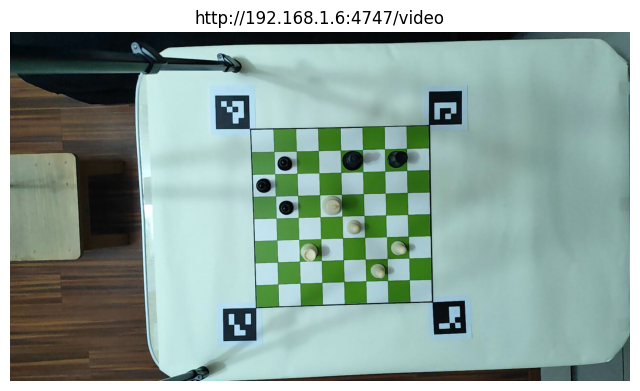

Probando: http://192.168.1.6:4747/mjpegfeed
  Sin video
Probando: http://192.168.1.6:4747/video?640x480
  OK (480, 640, 3)


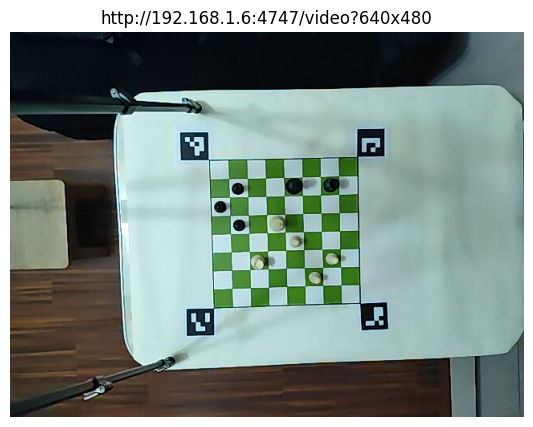

Probando: http://192.168.1.6:4747/
  Sin video
Probando: http://10.204.120.246:4747/video
  Sin video
Probando: http://10.204.120.246:4747/mjpegfeed
  Sin video
Probando: http://10.204.120.246:4747/video?640x480
  Sin video
Probando: http://10.204.120.246:4747/
  Sin video
CAMERA_SOURCE = http://192.168.1.6:4747/video
Modelo cargado: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs\modelo_ajedrez_entrenamiento.pth
IMG_SIZE: 64
Clases: ['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']
Buscando tablero con 4 ArUco en fuente: http://192.168.1.6:4747/video
Tablero detectado en frame 1. ArUco detectados: 4


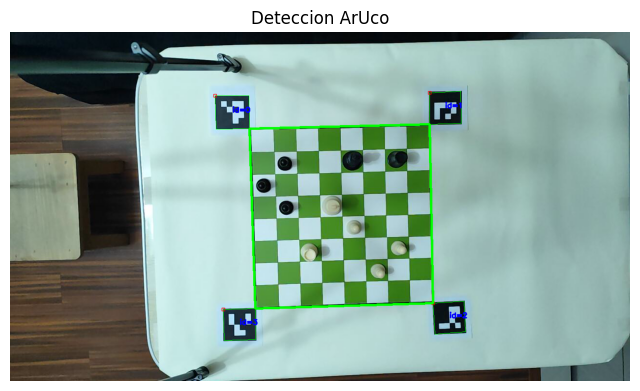

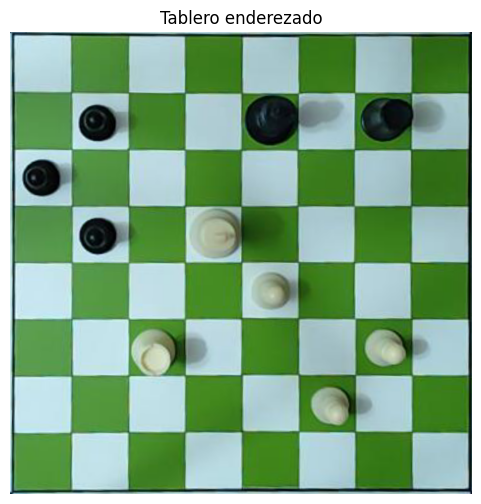

   a b c d e f g h
8   . . . . . . . .
7   . p . . k . r .
6   p . . . . . . .
5   . p . K . . . .
4   . . . . . . . .
3   . . P . . . P .
2   . . . . . . . .
1   . . . . . . . .


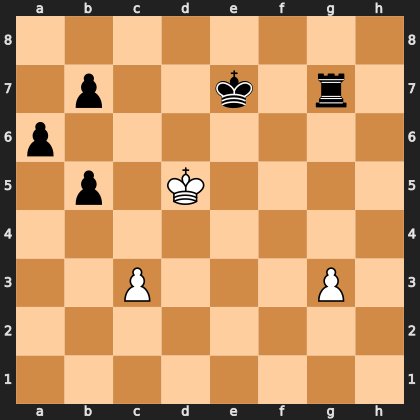

FEN: 8/1p2k1r1/p7/1p1K4/8/2P3P1/8/8 b - - 0 1
StockFish: c:\Users\User\Desktop\Brazo Robotico\StockFish\stockfish-windows-x86-64-avx2.exe
Motor UCI: subprocess sincronico
Jugada de negras: a6a5 SAN: a5
Movimiento fisico pendiente para el brazo: a6a5


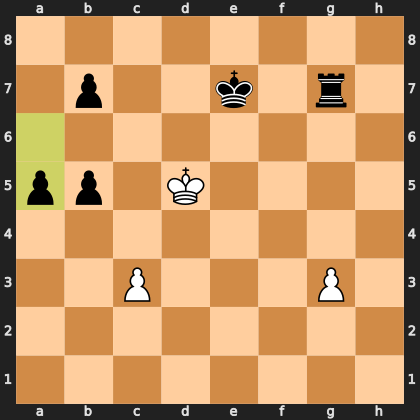

FEN: 8/1p2k1r1/8/pp1K4/8/2P3P1/8/8 w - - 0 2
Predicciones guardadas: c:\Users\User\Desktop\Brazo Robotico\Dataset\integracion_camara_stockfish\predicciones_20260528_012332.json
Matriz guardada: c:\Users\User\Desktop\Brazo Robotico\Dataset\integracion_camara_stockfish\matriz_20260528_012332.json


In [17]:
# Parche local para Jupyter/Windows: esta celda sobrescribe cualquier abrir_stockfish viejo en memoria.
# Si vuelve a salir el error anterior, reinicia kernel o ejecuta esta celda completa otra vez.
class StockfishUCI:
    def __init__(self, path, timeout=10):
        self.path = str(path)
        self.timeout = timeout
        self.proc = subprocess.Popen(
            [self.path],
            stdin=subprocess.PIPE,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
            universal_newlines=True,
        )
        self._send("uci")
        self._read_until("uciok")
        self._send("isready")
        self._read_until("readyok")

    def _send(self, command):
        if self.proc.poll() is not None:
            raise RuntimeError("StockFish se cerro inesperadamente.")
        self.proc.stdin.write(command + "\n")
        self.proc.stdin.flush()

    def _read_until(self, token):
        lines = []
        start = time.time()
        while True:
            if time.time() - start > self.timeout:
                raise TimeoutError(f"StockFish no respondio con {token!r}.")
            line = self.proc.stdout.readline()
            if not line:
                continue
            line = line.strip()
            lines.append(line)
            if token in line:
                return lines

    def play(self, board, time_limit=0.5):
        self._send("position fen " + board.fen())
        self._send(f"go movetime {int(time_limit * 1000)}")
        lines = self._read_until("bestmove")
        bestmove_line = [line for line in lines if line.startswith("bestmove")][-1]
        parts = bestmove_line.split()
        if len(parts) < 2 or parts[1] == "(none)":
            return None
        return chess.Move.from_uci(parts[1])

    def quit(self):
        if self.proc.poll() is None:
            try:
                self._send("quit")
            except Exception:
                pass
            self.proc.terminate()


def encontrar_stockfish():
    for path in STOCKFISH_CANDIDATES:
        if Path(path).exists():
            return Path(path)
    raise FileNotFoundError("No se encontro StockFish. Revisa STOCKFISH_CANDIDATES.")


def abrir_stockfish():
    path = encontrar_stockfish()
    print("StockFish:", path)
    print("Motor UCI: subprocess sincronico")
    return StockfishUCI(path)


def pedir_jugada_negras(board, engine, time_limit=STOCKFISH_TIME_LIMIT):
    board_engine = board.copy(stack=False)
    board_engine.turn = chess.BLACK

    if board_engine.is_game_over():
        print("La partida ya termino segun python-chess.")
        return None, board_engine

    move = engine.play(board_engine, time_limit=time_limit)
    if move is None:
        print("StockFish no encontro jugada.")
        return None, board_engine

    san = board_engine.san(move)
    board_engine.push(move)
    print("Jugada de negras:", move.uci(), "SAN:", san)
    print("Movimiento fisico pendiente para el brazo:", move.uci())
    return move, board_engine

def ejecutar_turno_negras(source=None, engine=None, time_limit=STOCKFISH_TIME_LIMIT, mostrar_segmentos=False):
    if source is None:
        source = CAMERA_SOURCE

    recargar_modelo_clasificacion(MODEL_PATH)

    frame, tablero_recto, timestamp = capturar_tablero(source)
    if tablero_recto is None:
        return None

    casillas = segmentar_casillas(tablero_recto)
    if mostrar_segmentos:
        mostrar_casillas(casillas)

    predicciones = clasificar_casillas(casillas)
    matriz, board_detectado = predicciones_a_matriz_y_board(predicciones, turn=chess.BLACK)

    mostrar_matriz(matriz)
    mostrar_board(board_detectado)

    fen_manual = input("Si necesitas corregir la posicion, pega FEN aqui. Enter para continuar: ").strip()
    if fen_manual:
        board_detectado = chess.Board(fen_manual)
        board_detectado.turn = chess.BLACK
        mostrar_board(board_detectado)

    engine_externo = engine is not None
    if engine is None:
        engine = abrir_stockfish()

    try:
        move, board_actualizado = pedir_jugada_negras(board_detectado, engine, time_limit=time_limit)
    finally:
        if not engine_externo:
            engine.quit()

    if move is not None:
        mostrar_board(board_actualizado, move=move)

    out_json = CAMERA_OUTPUT_DIR / f"predicciones_{timestamp}.json"
    out_matrix = CAMERA_OUTPUT_DIR / f"matriz_{timestamp}.json"
    with open(out_json, "w", encoding="utf-8") as f:
        json.dump(predicciones, f, ensure_ascii=False, indent=2)
    with open(out_matrix, "w", encoding="utf-8") as f:
        json.dump({
            "matriz": matriz,
            "fen_detectado": board_detectado.fen(),
            "move_stockfish": move.uci() if move else None,
            "fen_actualizado": board_actualizado.fen() if move else None,
        }, f, ensure_ascii=False, indent=2)

    print("Predicciones guardadas:", out_json)
    print("Matriz guardada:", out_matrix)

    return {
        "frame": frame,
        "tablero_recto": tablero_recto,
        "casillas": casillas,
        "predicciones": predicciones,
        "matriz": matriz,
        "board_detectado": board_detectado,
        "move": move,
        "board_actualizado": board_actualizado if move else None,
    }

# Uso recomendado:
urls_ok = probar_urls_droidcam()
if urls_ok: usar_fuente_ip(urls_ok[0])
resultado = ejecutar_turno_negras(CAMERA_SOURCE, mostrar_segmentos=False)


## 10. Modo partida por turnos

Despues de que StockFish indique la jugada negra, mueves fisicamente esa pieza. Luego haces tu jugada blanca fisicamente y vuelves a ejecutar `ejecutar_turno_negras`.

In [ ]:
# Mantener StockFish abierto ahorra tiempo entre turnos.
# engine = abrir_stockfish()
# resultado = ejecutar_turno_negras(CAMERA_SOURCE, engine=engine, mostrar_segmentos=False)
# Cuando termines:
# engine.quit()


## 11. Prueba sin camara con un tablero enderezado guardado

In [ ]:
def probar_con_imagen_enderezada(image_path=None, engine=None):
    if image_path is None:
        candidatos = sorted((DATASET_DIR / "prueba_clasificacion_camara").glob("tablero_enderezado_*.jpg"))
        if not candidatos:
            candidatos = sorted((DATASET_DIR / "prueba_camara").glob("tablero_enderezado_*.jpg"))
        if not candidatos:
            raise FileNotFoundError("No encontre tableros enderezados guardados.")
        image_path = candidatos[-1]

    recargar_modelo_clasificacion(MODEL_PATH)
    tablero = cv2.imread(str(image_path))
    if tablero is None:
        raise FileNotFoundError(image_path)

    mostrar_frame_notebook(tablero, titulo=f"Tablero: {image_path.name}", figsize=(6, 6))
    casillas = segmentar_casillas(tablero)
    predicciones = clasificar_casillas(casillas)
    matriz, board = predicciones_a_matriz_y_board(predicciones, turn=chess.BLACK)
    mostrar_matriz(matriz)
    mostrar_board(board)

    engine_externo = engine is not None
    if engine is None:
        engine = abrir_stockfish()
    try:
        move, board_actualizado = pedir_jugada_negras(board, engine)
    finally:
        if not engine_externo:
            engine.quit()
    if move:
        mostrar_board(board_actualizado, move=move)
    return board, predicciones, move, board_actualizado

# board_prueba, predicciones_prueba, move_prueba, board_act = probar_con_imagen_enderezada()
